In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.metrics import confusion_matrix, classification_report

torch.manual_seed(42)
np.random.seed(42)

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("төхөөрөмж:", device)
if device == "cuda":
    print(torch.cuda.get_device_name(0))

төхөөрөмж: mps


In [2]:
IMG_SIZE = 112
BATCH = 128

train_set = datasets.MNIST("./data", train=True, download=True, transform=transforms.ToTensor())
test_set = datasets.MNIST("./data", train=False, download=True, transform=transforms.ToTensor())

train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True, num_workers=2)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)

print("train:", len(train_set), "| test:", len(test_set))
x, y = next(iter(train_loader))
print("нэг batch:", tuple(x.shape), tuple(y.shape))

train: 60000 | test: 10000


нэг batch: (128, 1, 28, 28) (128,)


In [3]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


def prep(x):
    """(B,1,28,28), [0,1] -> (B,3,112,112), ImageNet-ийн normalize"""
    x = x.to(device)
    x = F.interpolate(x, size=IMG_SIZE, mode="bilinear", align_corners=False)
    x = x.repeat(1, 3, 1, 1)
    return (x - MEAN) / STD

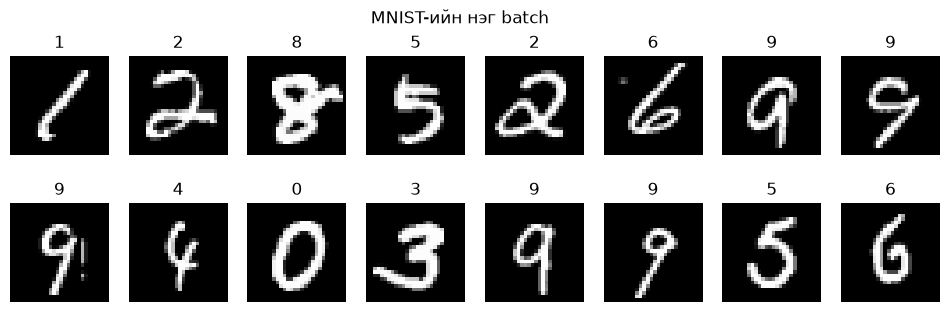

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x[i, 0], cmap="gray")
    ax.set_title(int(y[i]))
    ax.axis("off")
plt.suptitle("MNIST-ийн нэг batch")
plt.show()

In [5]:
weights = EfficientNet_B0_Weights.IMAGENET1K_V1
model = efficientnet_b0(weights=weights)

print(model.classifier)
print(f"параметр: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)
параметр: 5.29M


In [6]:
# ImageNet-ийн 1000 ангитай сүүлийн давхаргыг MNIST-ийн 10 ангитай давхаргаар солино
in_features = model.classifier[1].in_features      # 1280
model.classifier[1] = nn.Linear(in_features, 10)

model = model.to(device)
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=10, bias=True)
)


In [7]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        out = model(prep(x))
        preds.append(out.argmax(1).cpu())
        labels.append(y)
    preds = torch.cat(preds).numpy()
    labels = torch.cat(labels).numpy()
    return (preds == labels).mean(), preds, labels


acc0, _, _ = evaluate(model, test_loader)
print(f"finetune-аас өмнө тест: {acc0:.4f}")

finetune-аас өмнө тест: 0.0900


In [8]:
EPOCHS = 2
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
history = []

In [9]:
for epoch in range(EPOCHS):
    model.train()
    t0 = time.time()
    running, seen = 0.0, 0

    for x, y in train_loader:
        x, y = prep(x), y.to(device)

        optimizer.zero_grad()             # өмнөх градиентыг тэглэнэ
        out = model(x)                    # шууд тархалт
        loss = criterion(out, y)          # cross-entropy
        loss.backward()                   # гэдрэг тархалт
        optimizer.step()                  # жинг шинэчилнэ

        history.append(loss.item())
        running += loss.item() * len(y)
        seen += len(y)

    acc, _, _ = evaluate(model, test_loader)
    print(f"epoch {epoch + 1}/{EPOCHS} | train loss {running / seen:.4f} | "
          f"test acc {acc:.4f} | {time.time() - t0:.0f}s")

epoch 1/2 | train loss 0.0959 | test acc 0.9927 | 341s


epoch 2/2 | train loss 0.0256 | test acc 0.9933 | 243s


In [10]:
test_acc, preds, labels = evaluate(model, test_loader)
print(f"Тестийн нарийвчлал: {test_acc:.4f}  ({(preds != labels).sum()} / {len(labels)} алдаа)")
print()
print(classification_report(labels, preds, digits=4))

Тестийн нарийвчлал: 0.9933  (67 / 10000 алдаа)

              precision    recall  f1-score   support

           0     0.9969    0.9969    0.9969       980
           1     0.9930    0.9965    0.9947      1135
           2     0.9971    0.9922    0.9947      1032
           3     0.9960    0.9921    0.9940      1010
           4     0.9959    0.9837    0.9898       982
           5     0.9922    0.9944    0.9933       892
           6     0.9958    0.9927    0.9942       958
           7     0.9922    0.9942    0.9932      1028
           8     0.9858    0.9990    0.9924       974
           9     0.9881    0.9911    0.9896      1009

    accuracy                         0.9933     10000
   macro avg     0.9933    0.9933    0.9933     10000
weighted avg     0.9933    0.9933    0.9933     10000



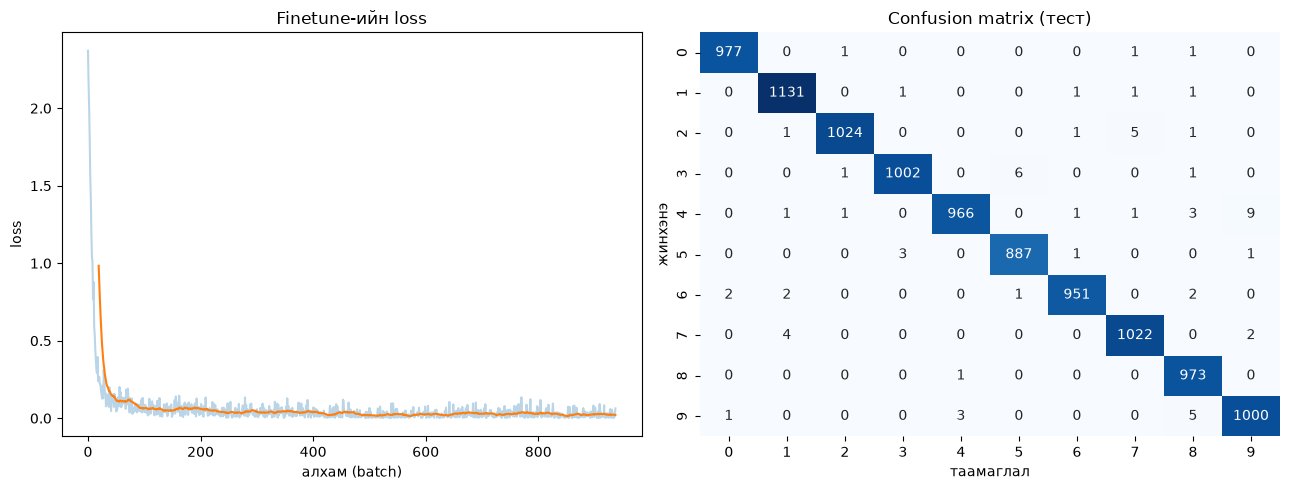

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

k = min(20, len(history))      # гулсах дундаж
ax[0].plot(history, alpha=0.3)
ax[0].plot(np.arange(k - 1, len(history)), np.convolve(history, np.ones(k) / k, mode="valid"))
ax[0].set_xlabel("алхам (batch)")
ax[0].set_ylabel("loss")
ax[0].set_title("Finetune-ийн loss")

cm = confusion_matrix(labels, preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[1])
ax[1].set_xlabel("таамаглал")
ax[1].set_ylabel("жинхэнэ")
ax[1].set_title("Confusion matrix (тест)")

plt.tight_layout()
plt.show()

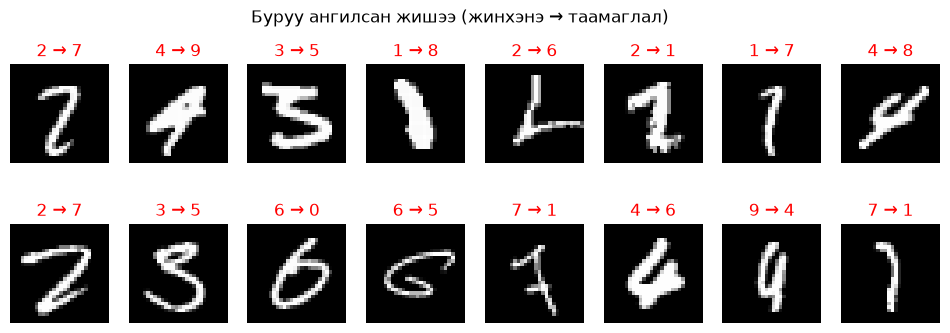

In [12]:
wrong = np.where(preds != labels)[0]
fig, axes = plt.subplots(2, 8, figsize=(12, 3.8))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, wrong[:16]):
    ax.imshow(test_set.data[i], cmap="gray")
    ax.set_title(f"{labels[i]} → {preds[i]}", color="red")
plt.suptitle("Буруу ангилсан жишээ (жинхэнэ → таамаглал)")
plt.show()